# Experiment 3: Synthetic Generalized Mixed-Variable Optimization

Evaluation of the **Generalized $(\mu, \lambda)$-Evolution Strategy** with synthetic benchmark functions combining all 6 variable types:
- **Real ($\mathbb{R}$)**: Continuous variables with Gaussian perturbation and log-normal self-adaptation $\sigma_{\text{real}}$
- **Count ($\mathbb{Z}$)**: Integer counts with Skellam mutation (Poisson difference) and log-normal self-adaptation $\lambda_{\text{count}}$
- **Binary ($\mathbb{B}$)**: Logit-mapped activation probabilities and logit-normal self-adaptation $\text{logit}_{\text{binary}}$
- **Categorical ($\mathbb{C}$)**: Softmax sampling over logit vectors and logit-normal self-adaptation $\text{logit}_{\text{cat}}$
- **Fuzzy ($\mathbb{F}$)**: Triangular control points $(a, b, c)$ with unit reflection, interlocking monotonicity ($a \le b \le c$), and log-normal self-adaptation $\sigma_{\text{fuzzy}}$
- **Circular ($\mathbb{S}^1$)**: Modular Skellam mutation on discrete ring ($\bmod k$) with log-normal self-adaptation $\lambda_{\text{circular}}$


In [2]:
from pathlib import Path
import sys
import os
import numpy as np
import matplotlib.pyplot as plt

# Ensure project root is in sys.path
cwd = Path.cwd().resolve()
project_root = None
for parent in [cwd] + list(cwd.parents):
    if (parent / "src").is_dir():
        project_root = parent
        break
if project_root is None:
    project_root = cwd.parent if (cwd.parent / "src").is_dir() else cwd

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# Force reload utils modules if cached in an active Jupyter session
import importlib
for mod_name in [
    "experiments.experiment_3.runners.plotting",
    "experiments.experiment_3.runners.runners",
]:
    if mod_name in sys.modules:
        importlib.reload(sys.modules[mod_name])

from src.es_model.config import ESConfig
from src.benchmarks.generalized_functions import GENERALIZED_BENCHMARKS
from experiments.experiment_3.runners.runners import (
    run_heterogeneous_benchmark_suite,
    run_heterogeneous_dynamics_tracking,
    build_heterogeneous_summary_table,
)
from experiments.experiment_3.runners.plotting import (
    plot_heterogeneous_convergence,
    plot_heterogeneous_dynamics,
)

print("Environment initialized successfully.")


## 1. Experiment Execution Configuration


In [3]:
# Experiment execution parameters
MAX_EVALS = 20000
N_SEEDS = 10
print(f">>> Experiment Parameters: {MAX_EVALS:,} evaluations, {N_SEEDS} seeds")

# Generalized genome configuration testing all 6 variable types
CONFIG = ESConfig(
    mu=15,
    lam=100,
    n_real=5,
    n_count=3,
    n_binary=4,
    n_categorical=2,
    categorical_k=np.array([3, 4], dtype=np.int64),
    n_fuzzy=2,
    n_circular=2,
    circular_k=np.array([7, 12], dtype=np.int64),
    seed=42,
)

print(f"\nGeneralized ES Hyperparameters:")
print(f"  Survivors (mu): {CONFIG.mu}, Offspring (lambda): {CONFIG.lam}")
print(f"  Active Dimensions: Real={CONFIG.n_real}, Count={CONFIG.n_count}, Binary={CONFIG.n_binary}, Categorical={CONFIG.n_categorical}, Fuzzy={CONFIG.n_fuzzy} (x3 pts), Circular={CONFIG.n_circular}")
print(f"  Total Active Genome Dimensionality (n_total): {CONFIG.n_total}")


>>> Experiment Parameters: 20,000 evaluations, 10 seeds

Generalized ES Hyperparameters:
  Survivors (mu): 15, Offspring (lambda): 100
  Active Dimensions: Real=5, Count=3, Binary=4, Categorical=2, Fuzzy=2 (x3 pts), Circular=2
  Total Active Genome Dimensionality (n_total): 20


## 2. Multi-Seed Optimization Execution

Executes the Generalized ES on all 3 synthetic benchmarks with random seeds:

In [4]:
SEEDS = [42 + i * 101 for i in range(N_SEEDS)]
data_dir = os.path.join(project_root, "experiments", "experiment_3", "data")
FIGURES_DIR = os.path.join(project_root, "experiments", "experiment_3", "figures")

results = run_heterogeneous_benchmark_suite(
    benchmarks=GENERALIZED_BENCHMARKS,
    config=CONFIG,
    seeds=SEEDS,
    max_evals=MAX_EVALS,
    data_dir=data_dir,
)



 Running Benchmark: Generalized_Sphere
 Convex separable mixed-variable benchmark across all 6 variable types
  Seed   143 ( 2/10) | Final Best Fitness: 9.325295e-07
  Seed   345 ( 4/10) | Final Best Fitness: 3.493150e-08
  Seed   547 ( 6/10) | Final Best Fitness: 1.646602e-08
  Seed   749 ( 8/10) | Final Best Fitness: 4.980082e-07
  Seed   951 (10/10) | Final Best Fitness: 1.289621e-08

 Running Benchmark: Generalized_Rastrigin
 Multi-modal non-convex mixed-variable benchmark with cosine oscillations
  Seed   143 ( 2/10) | Final Best Fitness: 9.950234e-01
  Seed   345 ( 4/10) | Final Best Fitness: 1.989941e+00
  Seed   547 ( 6/10) | Final Best Fitness: 2.984931e+00
  Seed   749 ( 8/10) | Final Best Fitness: 2.985146e+00
  Seed   951 (10/10) | Final Best Fitness: 9.949600e-01

 Running Benchmark: Generalized_Coupled
 Coupled mixed-variable benchmark with discrete regime switches
  Seed   143 ( 2/10) | Final Best Fitness: 3.696442e-07
  Seed   345 ( 4/10) | Final Best Fitness: 5.126021

## 3. Convergence Curves (Fitness vs. Evaluations)

Plots the mean fitness convergence curve with $\pm 1$ standard deviation across all random seeds:

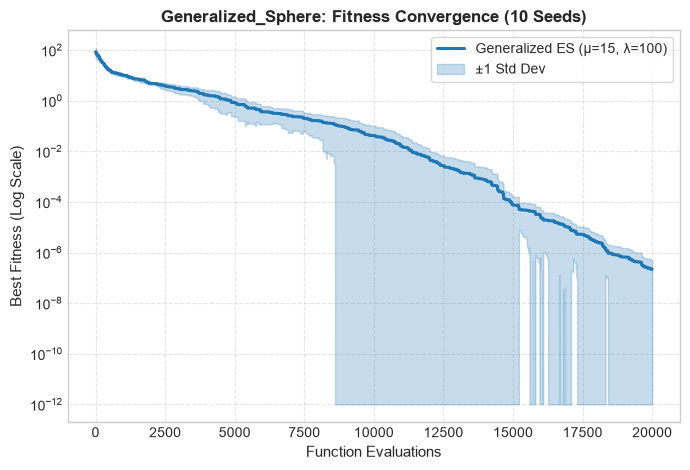

Saved separate convergence figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_sphere_convergence.png


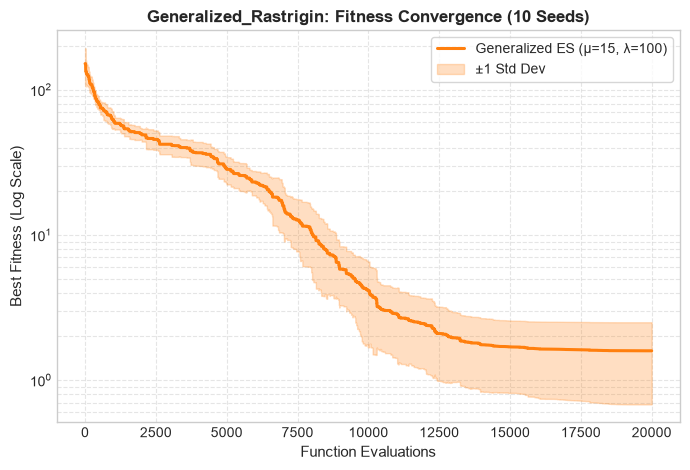

Saved separate convergence figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_rastrigin_convergence.png


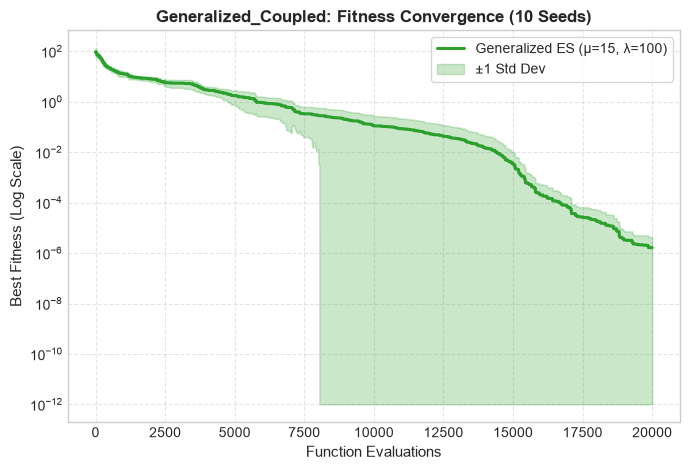

Saved separate convergence figure: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_coupled_convergence.png


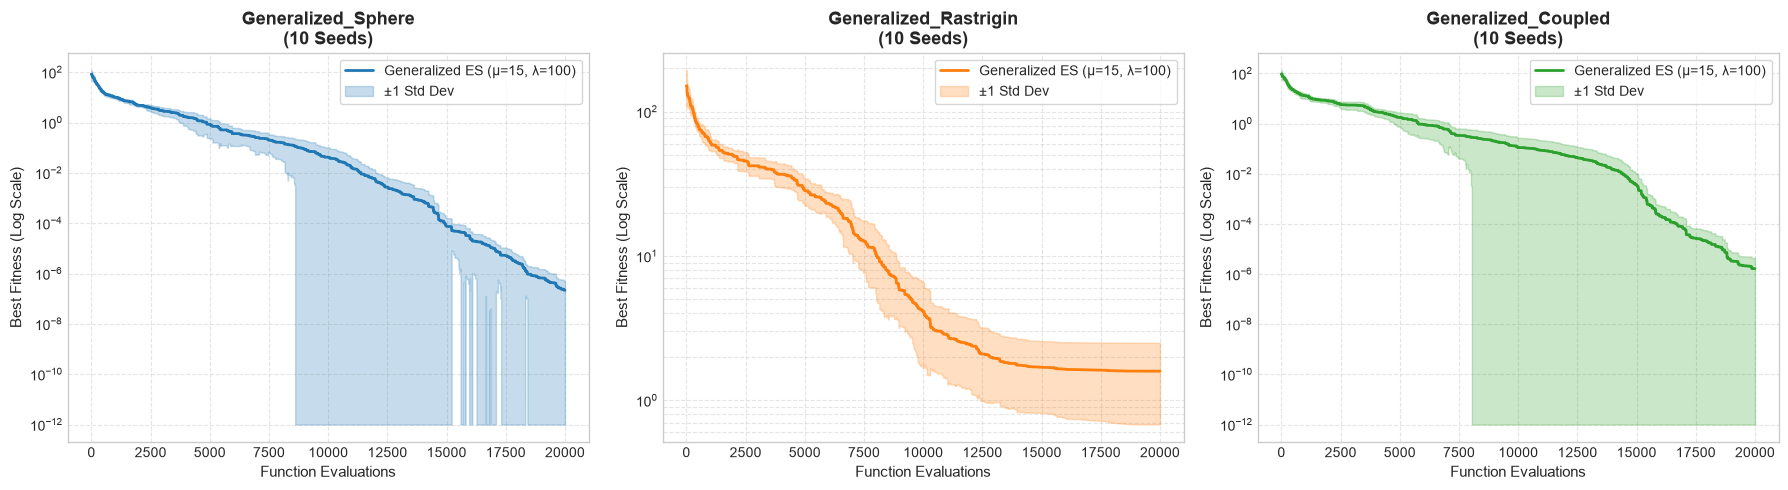

In [5]:
plot_heterogeneous_convergence(
    results=results,
    max_evals=MAX_EVALS,
    config=CONFIG,
    n_seeds=N_SEEDS,
    data_dir=data_dir,
)


## 4. Heterogeneous Variable & Strategy Dynamics (Multi-Seed Analysis)

Comprehensive 3-panel diagnostic tracking of all 6 decision variable types across all benchmark functions (Mean $\pm 1$ Std across all random seeds):
- **Panel A (Mutation Intensities & Step Sizes)**: Log-scale evolution of continuous and discrete step rates ($\sigma_{\text{real}}, \lambda_{\text{count}}, \sigma_{\text{fuzzy}}, \lambda_{\text{circular}}$).
- **Panel B (Probabilities & Information Certainty)**: Bounded $[0, 1]$ metrics tracking binary flip probability $p_{\text{flip}} = \sigma(\text{logit}_{\text{binary}})$, categorical maximum confidence $\max(p)$, and normalized Shannon entropy $H(p)/\ln(K)$ demonstrating uncertainty collapse.
- **Panel C (Fitness Error Decomposition)**: Log-scale partial fitness contributions ($f_{\text{real}}, f_{\text{count}}, f_{\text{binary}}, f_{\text{cat}}, f_{\text{fuzzy}}, f_{\text{circular}}$) revealing the exact sequence and generation of resolution for each variable type.

>>> Tracking Heterogeneous Dynamics: Generalized_Sphere (10 Seeds)


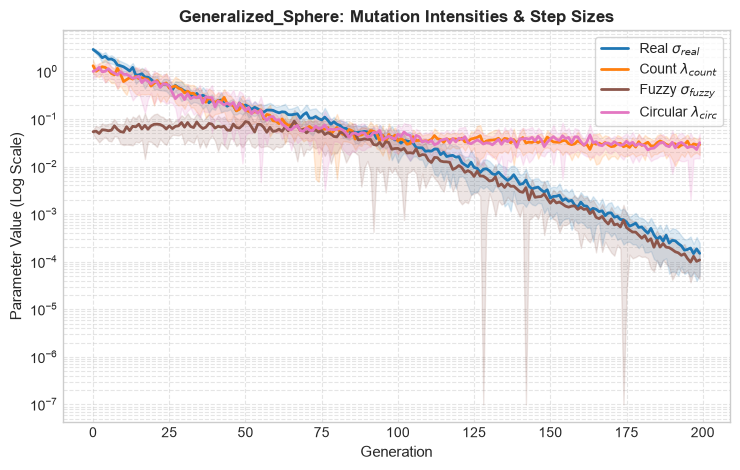

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_sphere_step_sizes.png


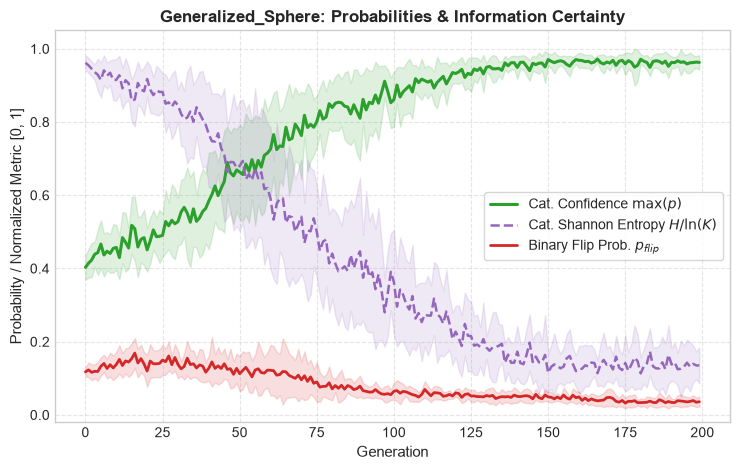

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_sphere_probabilities.png


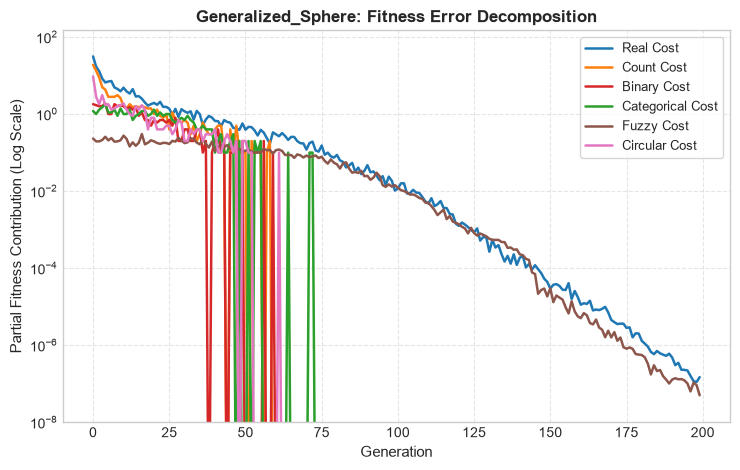

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_sphere_decomposition.png


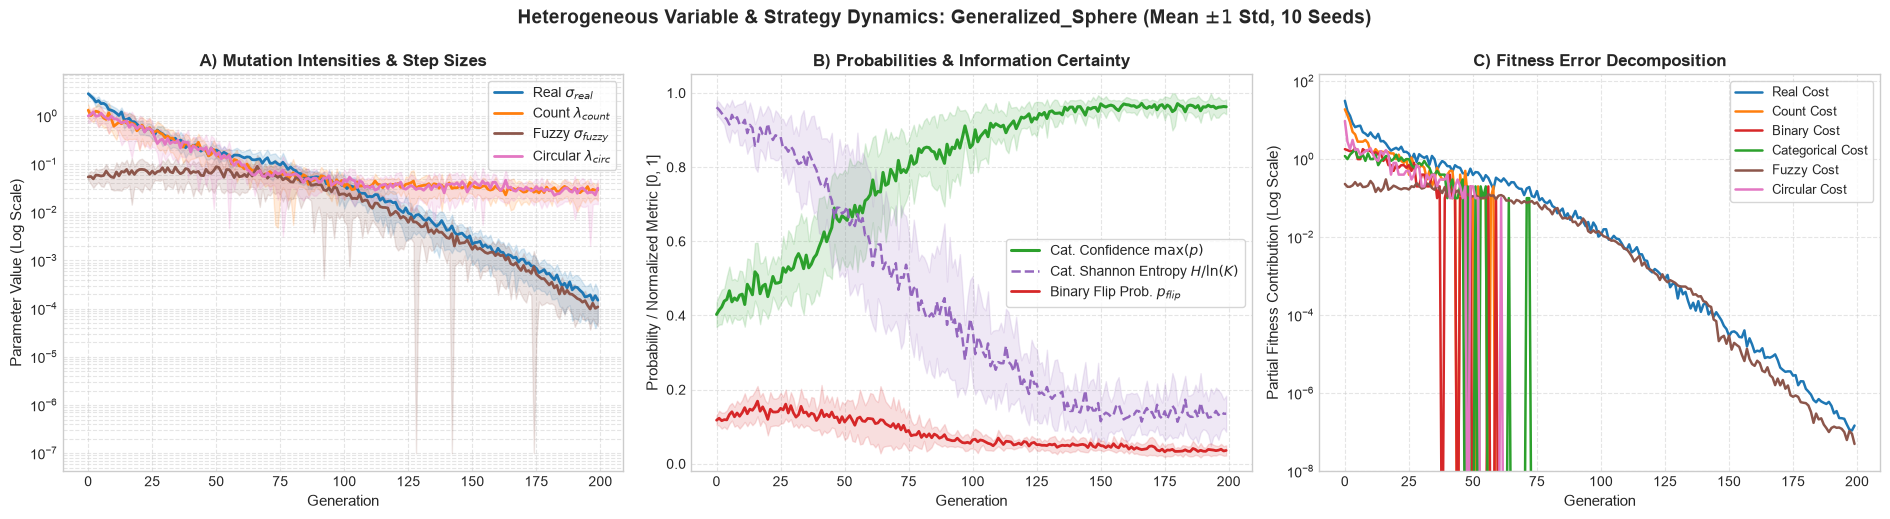

>>> Tracking Heterogeneous Dynamics: Generalized_Rastrigin (10 Seeds)


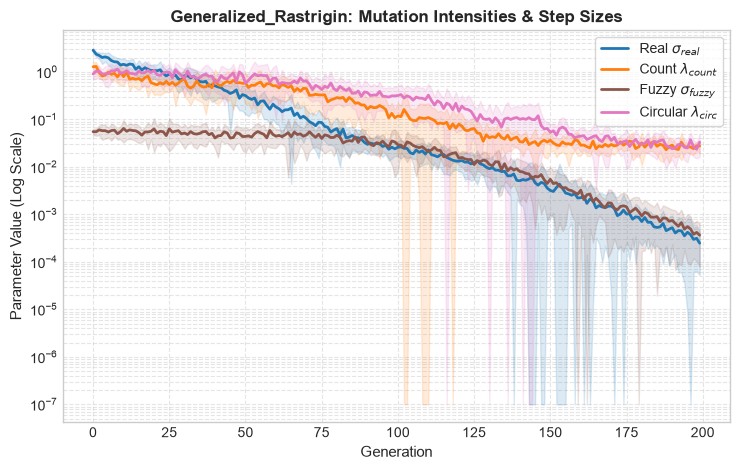

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_rastrigin_step_sizes.png


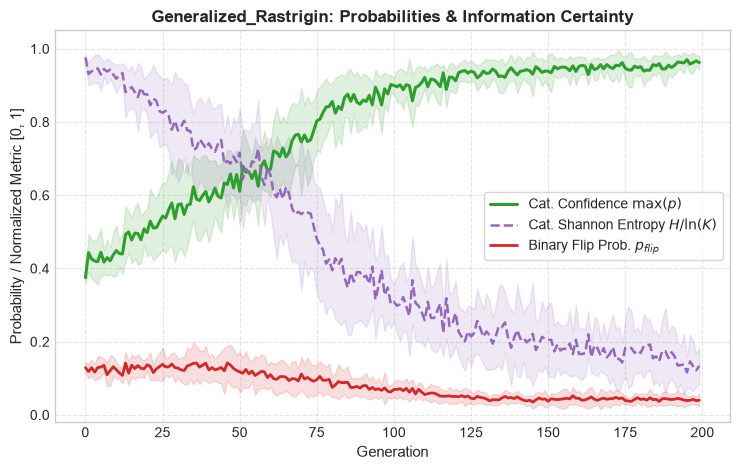

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_rastrigin_probabilities.png


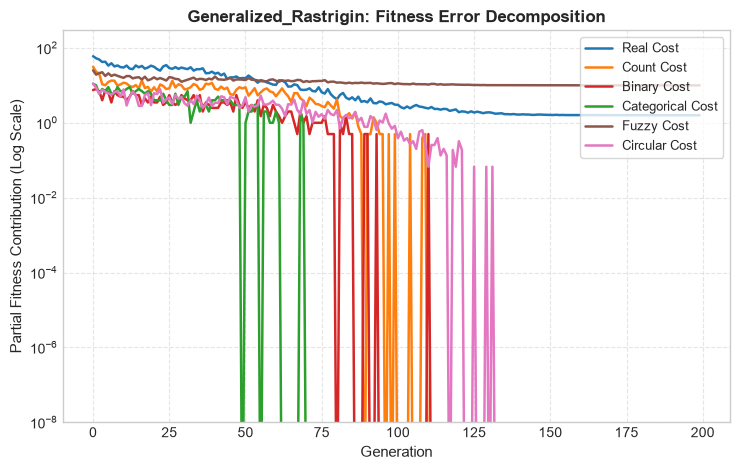

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_rastrigin_decomposition.png


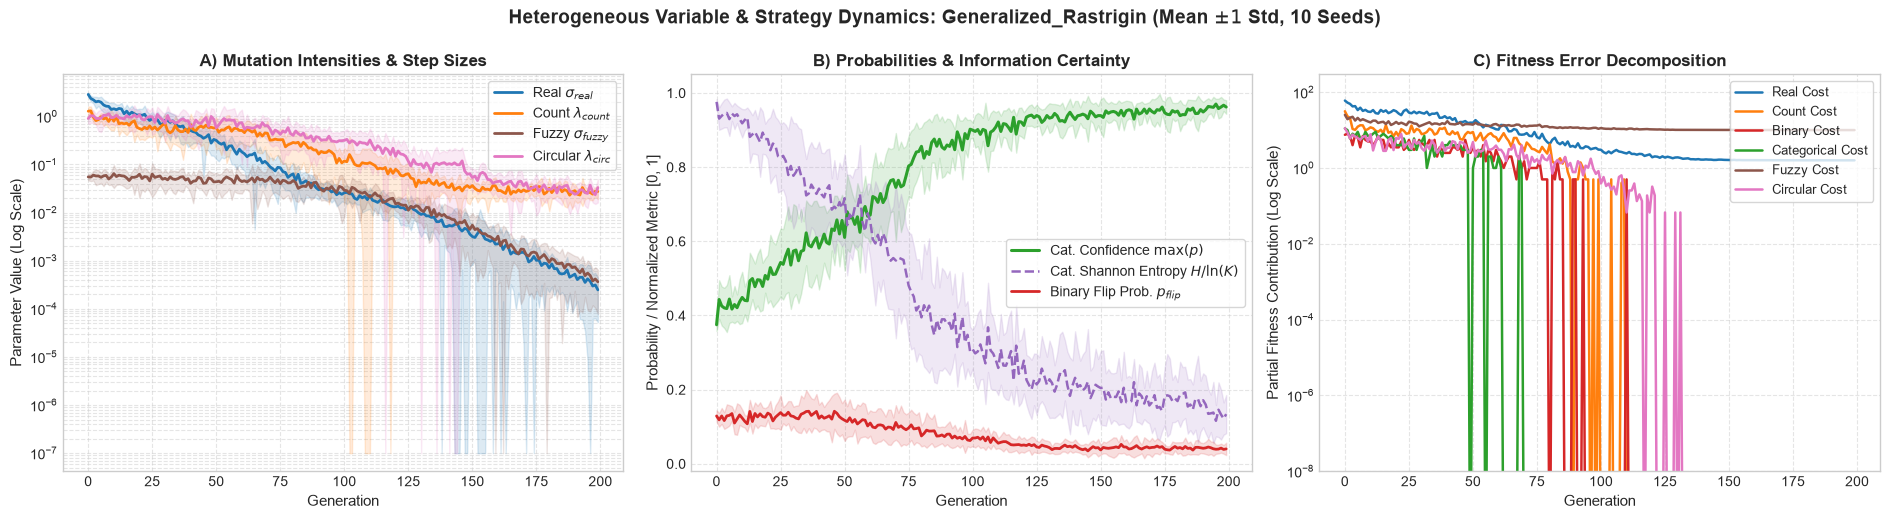

>>> Tracking Heterogeneous Dynamics: Generalized_Coupled (10 Seeds)


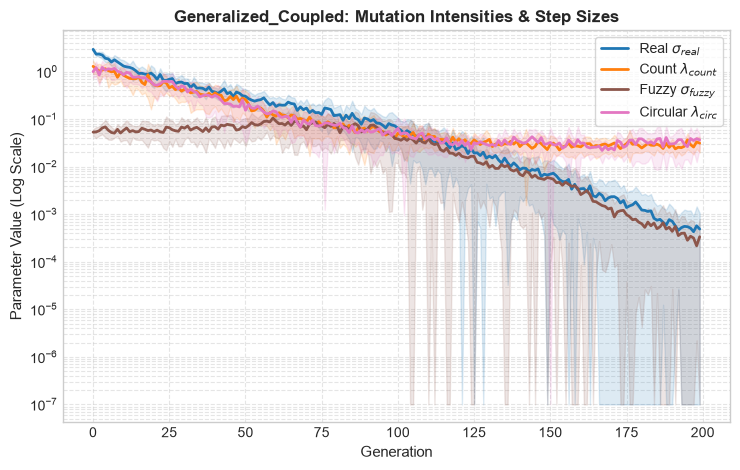

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_coupled_step_sizes.png


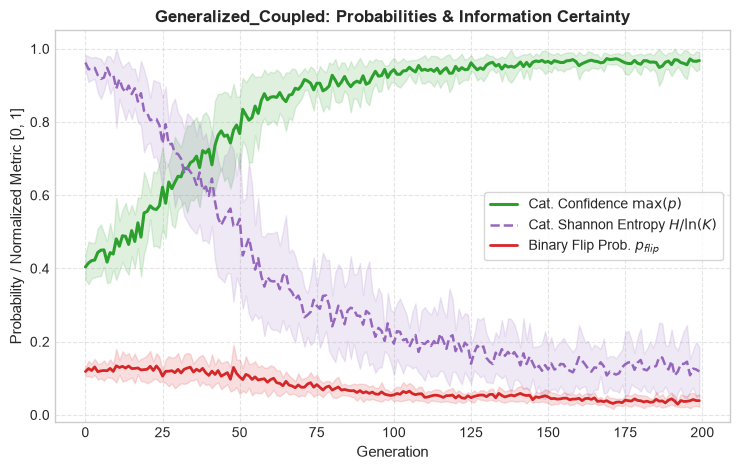

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_coupled_probabilities.png


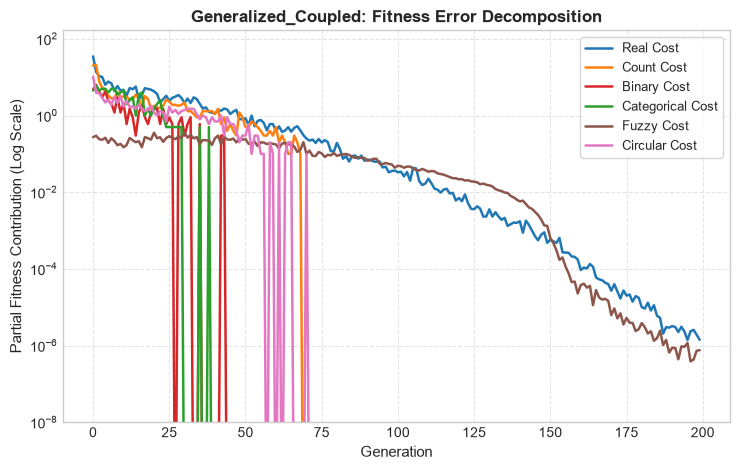

  Saved: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_generalized_coupled_decomposition.png


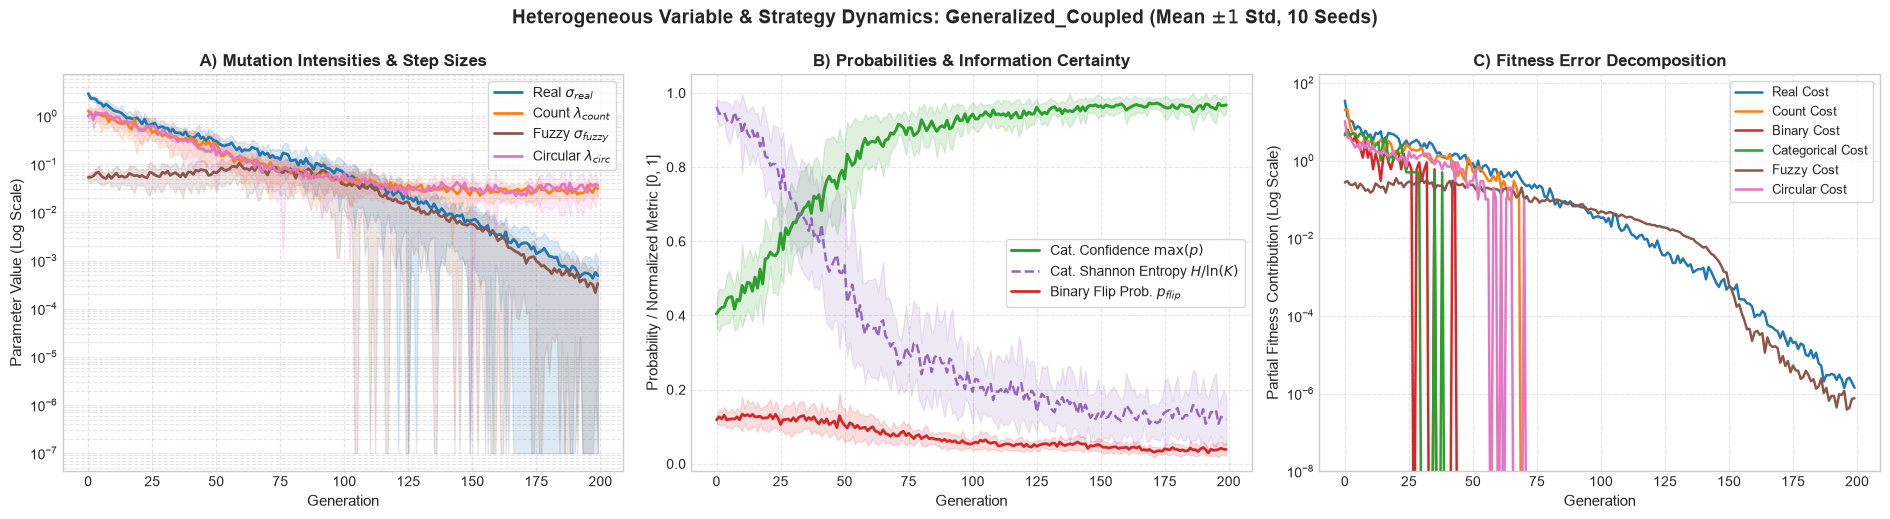


Successfully saved complete heterogeneous dynamics to: C:\Users\bejmo\Documents\documents\GitHub\TFG\experiments\data\experiment_3\exp3_strategy_dynamics.npz


In [6]:
all_saved_data, bench_dynamics = run_heterogeneous_dynamics_tracking(
    benchmarks=GENERALIZED_BENCHMARKS,
    config=CONFIG,
    seeds=SEEDS,
    max_evals=MAX_EVALS,
    data_dir=data_dir,
)

n_generations = MAX_EVALS // CONFIG.lam
for bench_name, bench_agg in bench_dynamics.items():
    plot_heterogeneous_dynamics(
        bench_name=bench_name,
        bench_agg=bench_agg,
        n_generations=n_generations,
        n_seeds=N_SEEDS,
        data_dir=data_dir,
)


## 5. Statistical Results Summary Table

In [7]:
summary_df = build_heterogeneous_summary_table(
    results=results,
    seeds=SEEDS,
    max_evals=MAX_EVALS,
)

print("=" * 90)
print(f" EXPERIMENT 3 RESULTS SUMMARY ({N_SEEDS} Seeds | {MAX_EVALS} Max Evaluations)")
print("=" * 90)
if hasattr(summary_df, "to_string"):
    print(summary_df.to_string(index=False))
else:
    for row in summary_df:
        print(row)
print("=" * 90)


 EXPERIMENT 3 RESULTS SUMMARY (10 Seeds | 20000 Max Evaluations)
Benchmark Function        | Mean Best Fitness    | Std Dev            | Min (Best Run)    
----------------------------------------------------------------------------------------
Generalized_Sphere        | 2.174433e-07         | 2.800798e-07       | 1.289621e-08      
Generalized_Rastrigin     | 1.592084e+00         | 9.118707e-01       | 3.741048e-05      
Generalized_Coupled       | 1.641572e-06         | 2.700746e-06       | 1.343297e-09      


## 6. Comparison with External Baselines (Table 5.3)

Compares Generalized ES performance against Uniform Random Search and Continuous CMA-ES with Rounding across the 3 heterogeneous benchmarks (10 seeds, 20,000 evaluations per seed), evaluating paired Wilcoxon signed-rank significance tests.


In [ ]:
from experiments.experiment_3.runners.run_experiment_3 import compute_wilcoxon_table_exp3

exp3_traces_file = os.path.join(data_dir, "exp3_traces.npz")
baseline_file = os.path.join(data_dir, "random_search_results.json")

print("=" * 115)
print(f"{'Benchmark':<24} | {'Opponent Baseline':<18} | {'W/T/L':<8} | {'Stat (W)':<9} | {'p-raw':<12} | {'p-adj':<12} | {'Decision'}")
print("=" * 115)
tests_exp3 = compute_wilcoxon_table_exp3(exp3_traces_file, baseline_file)
for bench_name, records in tests_exp3.items():
    for r in records:
        print(f"{bench_name:<24} | {r['opponent']:<18} | {r['wins']}/{r['ties']}/{r['losses']:<6} | {r['w_stat']:<9.1f} | {r['raw_p']:<12.4e} | {r['adj_p']:<12.4e} | {r['decision']}")
print("=" * 115)
